# Parts C and E: Evaluation and Grad-CAM
Team members: Yerkebulan Abdissattar, Daniyal Adilbekuly, Dias Tursunbai.


- **Part C:** loss/accuracy curves, test accuracy, confusion matrix, per-class precision/recall, most confused classes.
- **Part E:** Grad-CAM for 3 correct and 2 incorrect predictions.

### Setup: load Part A and the exported models
Takes `part_a.ipynb` (test loader, class names, preprocessing) and `artifacts/part_b_d/`.
Provides `models_by_name`, `histories`, `selected_name`, `test_loader`.

train: 100 images; first image (754, 500); label 0
val: 100 images; first image (606, 500); label 0
test: 322 images; first image (523, 500); label 0
All selected images loaded successfully
Class                                Train    Val   Test
0: pink primrose                        10     10     20
1: hard-leaved pocket orchid            10     10     40
2: canterbury bells                     10     10     20
3: sweet pea                            10     10     36
4: english marigold                     10     10     45
5: tiger lily                           10     10     25
6: moon orchid                          10     10     20
7: bird of paradise                     10     10     65
8: monkshood                            10     10     26
9: globe thistle                        10     10     25


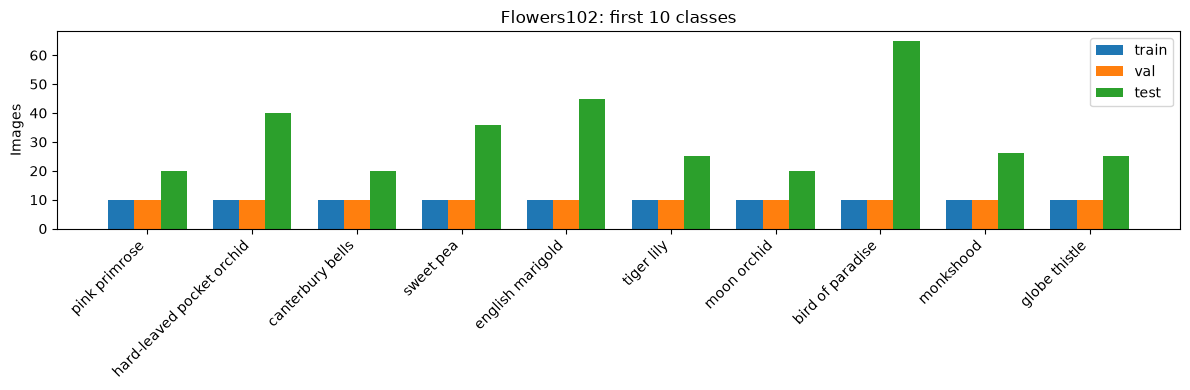

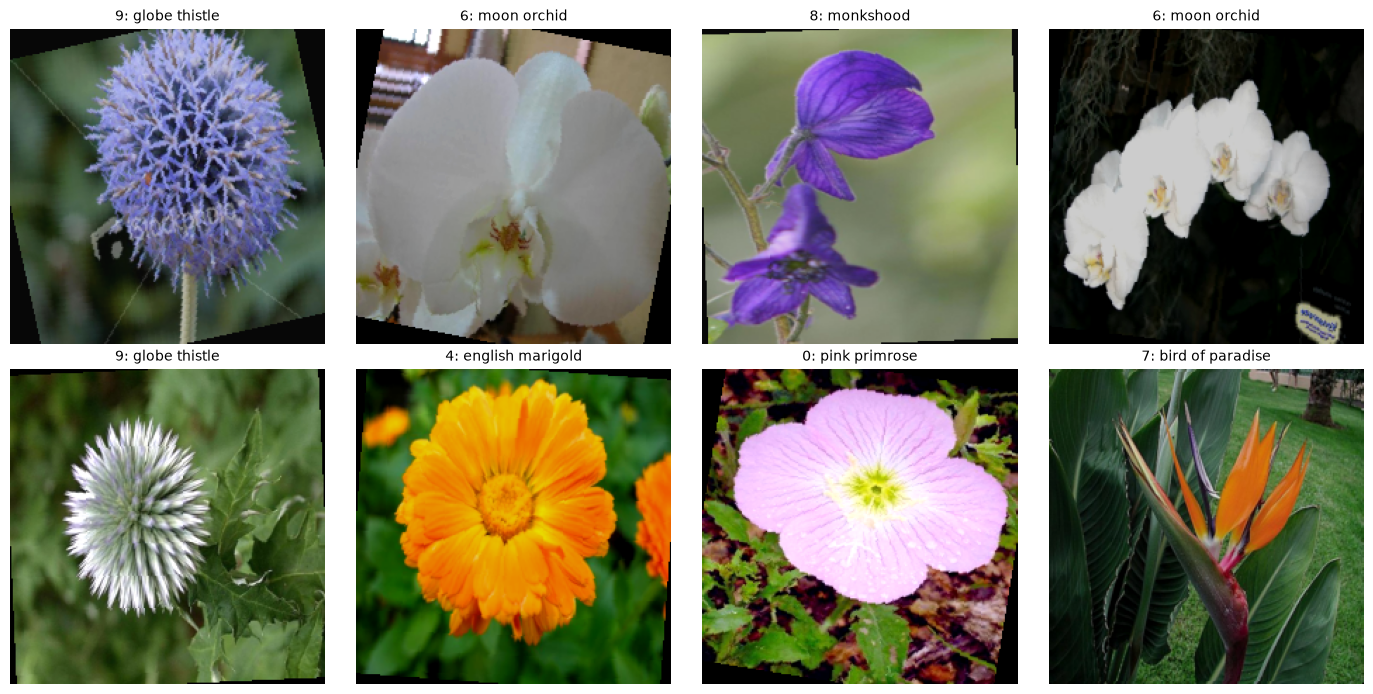

train: batch (32, 3, 224, 224), labels (32,)
val: batch (32, 3, 224, 224), labels (32,)
test: batch (32, 3, 224, 224), labels (32,)
Data pipeline checks passed
device: cpu | selected on validation: frozen


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torchvision import models
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from IPython.display import display

PART_A_PATH = Path("part_a.ipynb")
ART = Path("artifacts/part_b_d")
OUT = Path("artifacts/part_c_e")
OUT.mkdir(parents=True, exist_ok=True)

required_a = ("test_loader", "CLASS_NAMES", "IMAGE_SIZE", "NUM_CLASSES",
              "IMAGENET_MEAN", "IMAGENET_STD")
if not all(name in globals() for name in required_a):
    if not PART_A_PATH.is_file():
        raise FileNotFoundError("Place part_a.ipynb here or update PART_A_PATH")
    get_ipython().run_line_magic("run", f'"{PART_A_PATH.resolve().as_posix()}"')
missing = [name for name in required_a if name not in globals()]
if missing:
    raise RuntimeError("Missing Part A outputs: " + ", ".join(missing))

meta = json.loads((ART / "metadata.json").read_text(encoding="utf-8"))
class_names = meta["class_names"]
K = meta["num_classes"]
selected_name = meta["selected_setting"]          # chosen on validation macro-F1 in Part D
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_model(name):
    model = models.resnet18(weights=None)          # architecture only; weights come from our checkpoint
    model.fc = nn.Linear(model.fc.in_features, K)
    state = torch.load(ART / meta["checkpoints"][name]["file"], map_location="cpu")
    model.load_state_dict(state)
    return model.to(device).eval()

models_by_name = {name: load_model(name) for name in meta["checkpoints"]}
histories = {name: pd.read_csv(ART / f"history_{name}.csv") for name in models_by_name}
print("device:", device, "| selected on validation:", selected_name)

## Part C
### C1. Training and validation curves
Takes the epoch histories from Part B/D. The dashed line marks where stage 2 starts (epoch 5 to 6): `layer4` is unfrozen in `finetune`, the head keeps training in `frozen`.

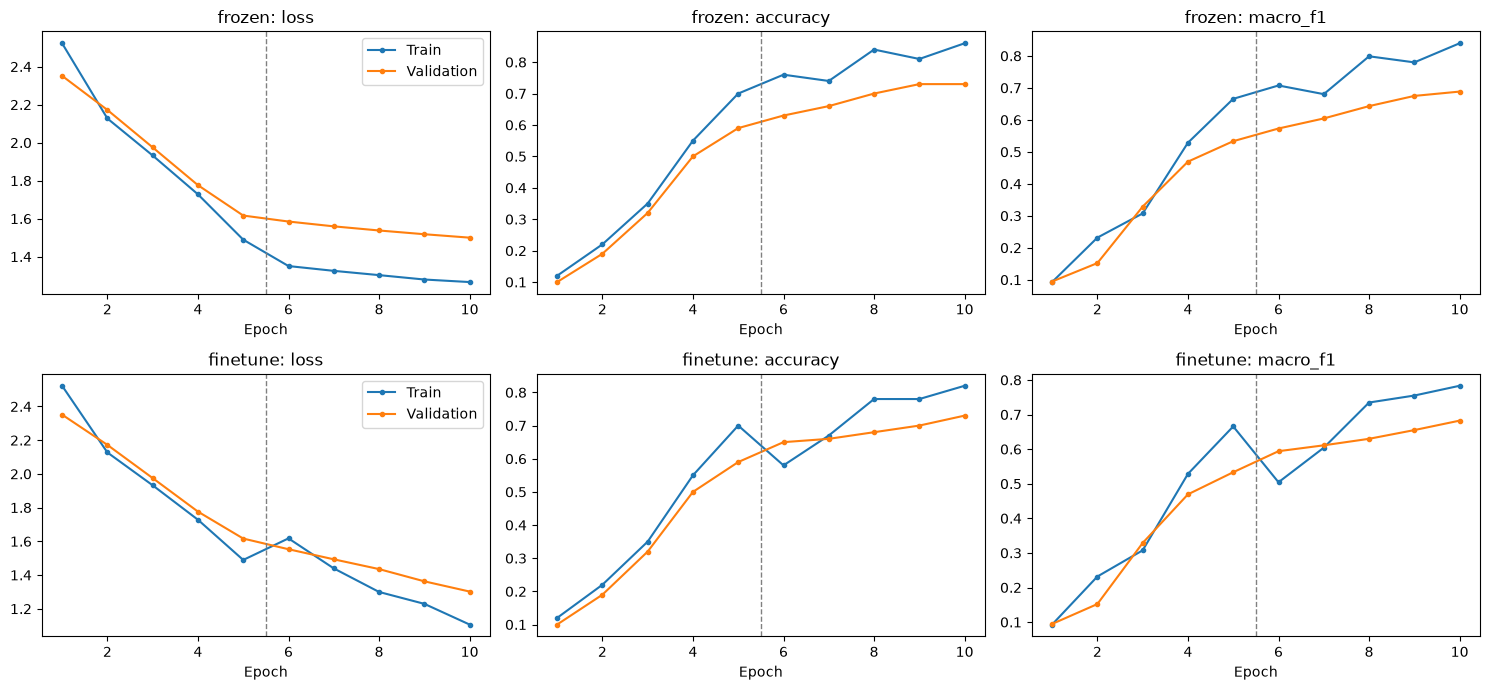

In [2]:
stage_split = histories[selected_name].query("stage == 'head'")["epoch"].max() + 0.5

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, name in enumerate(("frozen", "finetune")):
    h = histories[name]
    for col, metric in enumerate(("loss", "accuracy", "macro_f1")):
        ax = axes[row, col]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="Train")
        ax.plot(h["epoch"], h[f"val_{metric}"], marker="o", ms=3, label="Validation")
        ax.axvline(stage_split, color="gray", ls="--", lw=1)
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("Epoch")
        if col == 0:
            ax.legend()
plt.tight_layout()
fig.savefig(OUT / "03_training_curves.png", dpi=150)
plt.show()

### C2. Test predictions for both settings
Takes the test loader and both checkpoints. Provides `results[name] = (y_true, y_pred, confidence)`.

The test set is used only to report. The model was already chosen on validation macro-F1, so test does not change the choice.

,setting,selected,val_macro_f1,test_accuracy,test_macro_f1
0,frozen,True,0.6884,0.7671,0.6976
1,finetune,False,0.6825,0.7919,0.7283


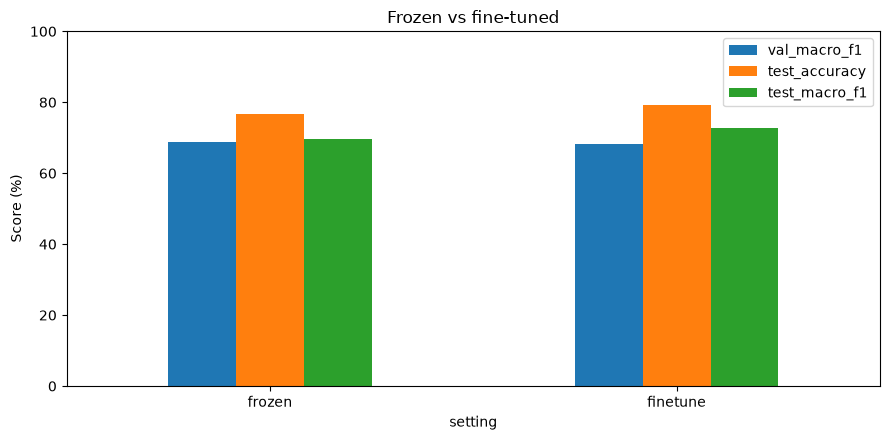

In [3]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    y_true, y_pred, conf = [], [], []
    for images, labels in loader:
        probs = model(images.to(device)).softmax(dim=1).cpu()
        c, p = probs.max(dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(p.tolist())
        conf.extend(c.tolist())
    return np.array(y_true), np.array(y_pred), np.array(conf)

results = {name: predict(model, test_loader) for name, model in models_by_name.items()}

rows = []
for name, (yt, yp, _) in results.items():
    rows.append({
        "setting": name,
        "selected": name == selected_name,
        "val_macro_f1": meta["checkpoints"][name]["val_macro_f1"],
        "test_accuracy": accuracy_score(yt, yp),
        "test_macro_f1": f1_score(yt, yp, labels=range(K), average="macro", zero_division=0),
    })
summary = pd.DataFrame(rows)
display(summary.round(4))
summary.to_csv(OUT / "summary_metrics.csv", index=False)

(summary.set_index("setting")[["val_macro_f1", "test_accuracy", "test_macro_f1"]] * 100).plot.bar(
    rot=0, figsize=(9, 4.5), ylim=(0, 100), ylabel="Score (%)", title="Frozen vs fine-tuned")
plt.tight_layout()
plt.savefig(OUT / "04_experiment.png", dpi=150)
plt.show()

### C3. Selected model: accuracy, confusion matrix, per-class precision/recall
Takes the predictions of the selected model. Provides `cm`, `report` and the most confused pair.

Selected model: frozen
Test accuracy : 0.7671
Test macro-F1 : 0.6976


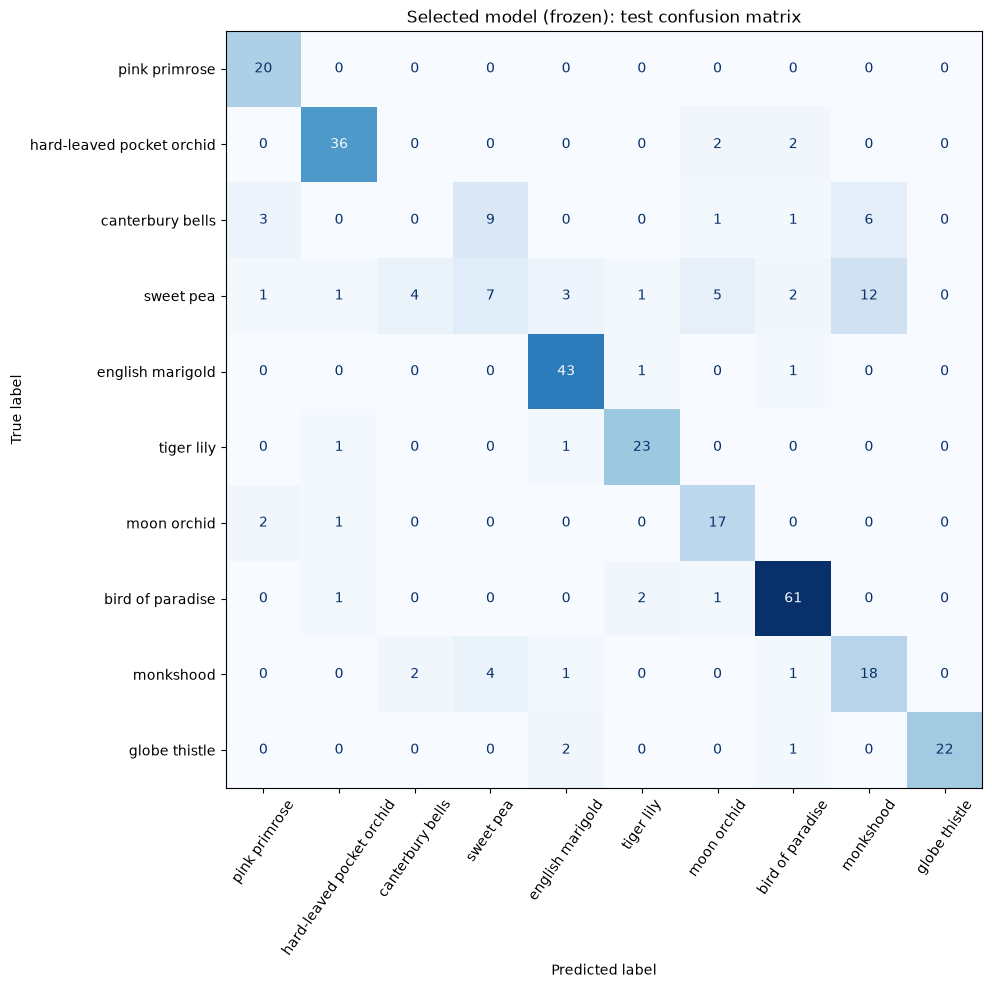

,precision,recall,f1-score,support
pink primrose,0.769,1.000,0.870,20.000
hard-leaved pocket orchid,0.900,0.900,0.900,40.000
canterbury bells,0.000,0.000,0.000,20.000
sweet pea,0.350,0.194,0.250,36.000
english marigold,0.860,0.956,0.905,45.000
tiger lily,0.852,0.920,0.885,25.000
moon orchid,0.654,0.850,0.739,20.000
bird of paradise,0.884,0.938,0.910,65.000
monkshood,0.500,0.692,0.581,26.000
globe thistle,1.000,0.880,0.936,25.000


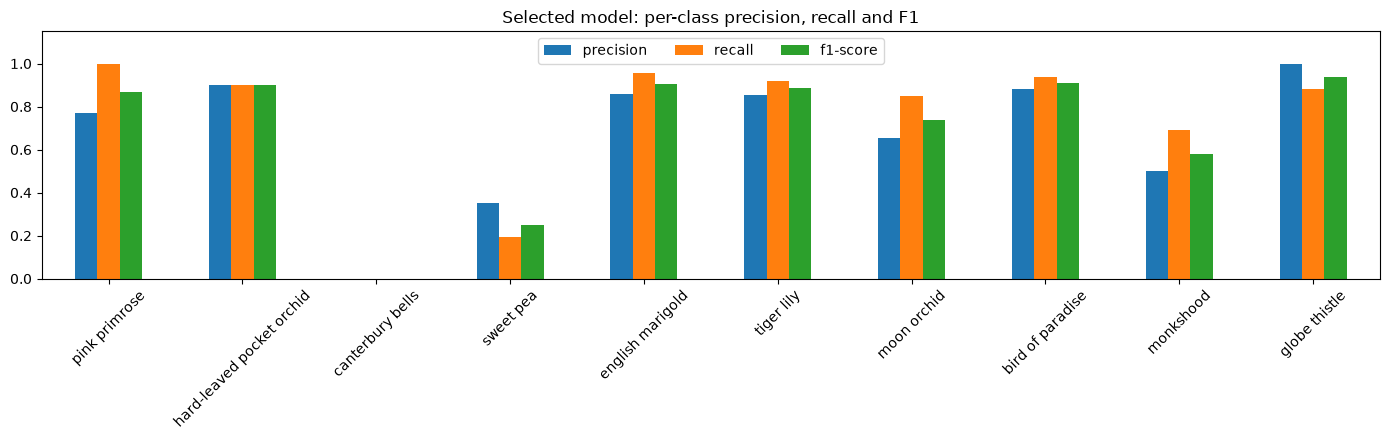

In [4]:
y_true, y_pred, conf = results[selected_name]
print(f"Selected model: {selected_name}")
print(f"Test accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Test macro-F1 : {f1_score(y_true, y_pred, labels=range(K), average='macro', zero_division=0):.4f}")

cm = confusion_matrix(y_true, y_pred, labels=range(K))      # rows = true class, columns = predicted class
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=55, colorbar=False)
ax.set_title(f"Selected model ({selected_name}): test confusion matrix")
plt.tight_layout()
fig.savefig(OUT / "05_confusion_matrix.png", dpi=150)
plt.show()

report = pd.DataFrame(classification_report(
    y_true, y_pred, labels=range(K), target_names=class_names,
    output_dict=True, zero_division=0)).T
display(report.round(3))
report.to_csv(OUT / "classification_report.csv")

ax = report.loc[class_names, ["precision", "recall", "f1-score"]].plot.bar(
    figsize=(14, 4.5), rot=45, ylim=(0, 1.15), title="Selected model: per-class precision, recall and F1")
ax.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.savefig(OUT / "06_per_class.png", dpi=150)
plt.show()

In [5]:
# Most confused pair = largest number of errors in both directions combined.
pair_errors = cm + cm.T
pairs = sorted(((pair_errors[i, j], i, j) for i in range(K) for j in range(i + 1, K)), reverse=True)
print("Most confused class pairs (errors in both directions):")
for total, i, j in pairs[:3]:
    print(f"  {class_names[i]} <-> {class_names[j]}: {total} errors "
          f"({class_names[i]} predicted as {class_names[j]}: {cm[i, j]}, "
          f"{class_names[j]} predicted as {class_names[i]}: {cm[j, i]})")

Most confused class pairs (errors in both directions):
  sweet pea <-> monkshood: 16 errors (sweet pea predicted as monkshood: 12, monkshood predicted as sweet pea: 4)
  canterbury bells <-> sweet pea: 13 errors (canterbury bells predicted as sweet pea: 9, sweet pea predicted as canterbury bells: 4)
  canterbury bells <-> monkshood: 8 errors (canterbury bells predicted as monkshood: 6, monkshood predicted as canterbury bells: 2)


### Analysis of Part C
- Both settings reduce validation loss; training accuracy ends above validation accuracy, so there is a generalization gap, but validation loss does not reverse in this short run.
- `frozen` has slightly higher validation macro-F1, so it is selected; `finetune` is better on test. Validation has only 100 images, so a 0.6-point difference is within noise.
- Test accuracy is higher than macro-F1 because large classes (bird of paradise) are recognised well while small, hard classes count equally in macro-F1.
- Weakest classes: canterbury bells (no correct predictions) and sweet pea. Most confused pair: **sweet pea / monkshood, 16 errors**.



## Part E
### E1. Grad-CAM implementation
Takes a model, an image and a target class. Provides a heatmap over the 224 x 224 image.

Grad-CAM: take the last convolutional feature maps `A` (`layer4`, 512 x 7 x 7). The gradient of the class score with respect to `A`, averaged over space, gives one weight per channel. The heatmap is `ReLU(sum_k weight_k * A_k)`, upsampled and scaled to [0, 1]. It shows which regions increased the score of the explained class.

In [6]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.activations = None
        self._hook = target_layer.register_forward_hook(self._save_activations)

    def _save_activations(self, module, inputs, output):
        self.activations = output

    def __call__(self, image, class_idx=None):
        # The input must require grad: with a frozen backbone no earlier parameter does,
        # so without it the activations would not be part of the autograd graph.
        x = image.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        score = logits[0, class_idx]
        (grads,) = torch.autograd.grad(score, self.activations)
        weights = grads.mean(dim=(2, 3), keepdim=True)                    # [1, 512, 1, 1]
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=image.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.numpy(), class_idx

    def close(self):
        self._hook.remove()

def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

### E2. Choose examples and plot
Takes the selected model and its test predictions. Provides 3 correct and 2 incorrect examples.

Selection is deterministic: the first test images, in dataset order, from distinct true classes (the test loader has `shuffle=False`, so predictions line up with the dataset).

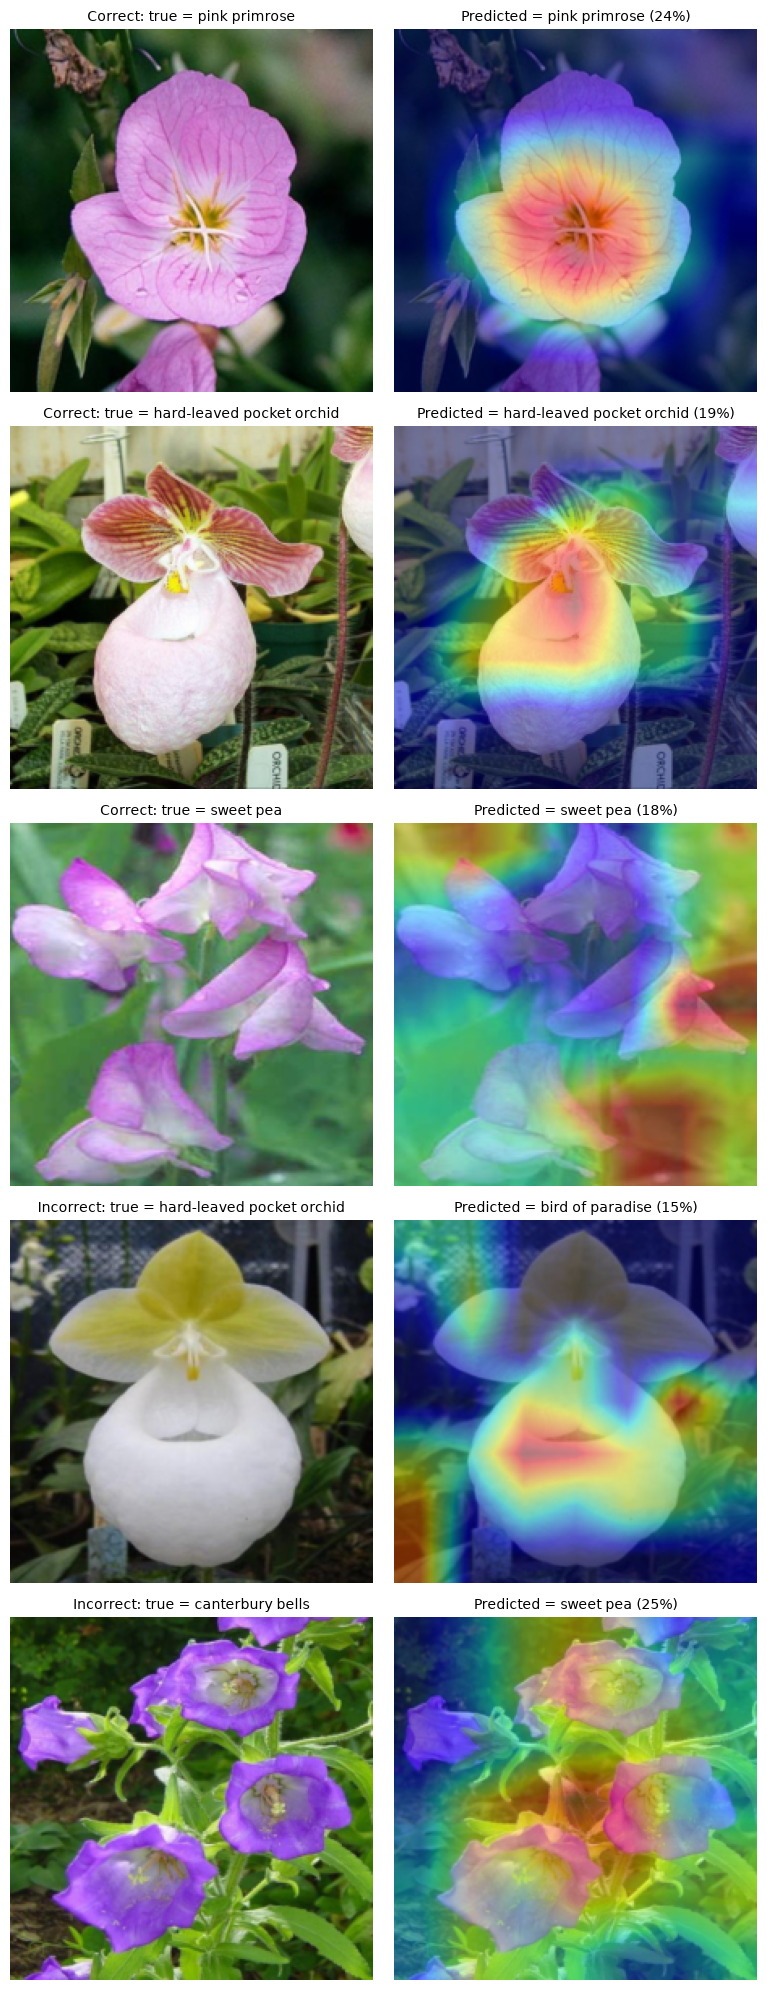

In [7]:
def first_distinct(indices, labels, k):
    chosen, seen = [], set()
    for i in indices:
        if labels[i] not in seen:
            chosen.append(int(i))
            seen.add(labels[i])
        if len(chosen) == k:
            break
    return chosen

correct_idx = first_distinct(np.where(y_true == y_pred)[0], y_true, 3)
wrong_idx = first_distinct(np.where(y_true != y_pred)[0], y_true, 2)
selected_model = models_by_name[selected_name]
cam_tool = GradCAM(selected_model, selected_model.layer4[-1])   # last residual block of layer4

examples = [("Correct", i) for i in correct_idx] + [("Incorrect", i) for i in wrong_idx]
fig, axes = plt.subplots(len(examples), 2, figsize=(8, 4 * len(examples)))
for row, (kind, i) in enumerate(examples):
    image, label = test_loader.dataset[i]
    cam, pred = cam_tool(image, class_idx=int(y_pred[i]))     # explain the PREDICTED class
    rgb = denormalize(image)
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"{kind}: true = {class_names[label]}", fontsize=10)
    axes[row, 1].imshow(rgb)
    axes[row, 1].imshow(cam, cmap="jet", alpha=0.45)
    axes[row, 1].set_title(f"Predicted = {class_names[pred]} ({conf[i]:.0%})", fontsize=10)
    for ax in axes[row]:
        ax.axis("off")
cam_tool.close()
plt.tight_layout()
fig.savefig(OUT / "08_grad_cam.png", dpi=150)
plt.show()

### Comments on Grad-CAM (Part E)
Heatmaps show regions that contributed to the predicted class score. The comments on the errors are hypotheses based on the visible patterns, not proof.

- **Correct, pink primrose:** strongest activation around the flower centre and inner petals.
- **Correct, hard-leaved pocket orchid:** the lower pouch and central region receive strong activation.
- **Correct, sweet pea:** activation also covers background regions, so a correct answer can still rely on context.
- **Incorrect, orchid -> bird of paradise:** activation covers the lower flower and some background. Locating the object does not guarantee the correct species.
- **Incorrect, canterbury bells -> sweet pea:** activation is spread across flowers and foliage, suggesting weak separation of similar-looking classes.